In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto definido por el siguiente cuadro de prelaciones inmediatas. En un grafo PERT dos actividades pueden salir del mismo nodo sólo si tienen exactamente las mismas predecesoras, y llegar al mismo nodo sólo si tienen exactamente las mismas sucesoras.

In [3]:
pregunta_1 = "1. ¿Pueden las actividades D y E compartir nodo inicial? ¿Y nodo final? Razónelo con el cuadro de prelaciones expandido.  "
pregunta_2 = "2. Misma pregunta para A y B, y para F y I.  "
pregunta_3 = "3. Enumere todas las parejas de actividades que pueden compartir nodo inicial y todas las que pueden compartir nodo final. Si una pareja puede compartir ambos, ¿qué ocurre?  "
pregunta_4 = "4. Dibuje el grafo PERT y compruebe sobre él las respuestas anteriores.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. ¿Pueden las actividades D y E compartir nodo inicial? ¿Y nodo final? Razónelo con el cuadro de prelaciones expandido.  

2. Misma pregunta para A y B, y para F y I.  

3. Enumere todas las parejas de actividades que pueden compartir nodo inicial y todas las que pueden compartir nodo final. Si una pareja puede compartir ambos, ¿qué ocurre?  

4. Dibuje el grafo PERT y compruebe sobre él las respuestas anteriores.  

In [4]:
#| tbl-cap: "Cuadro de prelaciones del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , '---'      ),
    ('D'     , 'A,B,C'    ),
    ('E'     , 'A,B,C'    ),
    ('F'     , 'D,E'      ),
    ('G'     , 'C'        ),
    ('H'     , 'F'        ),
    ('I'     , 'G,H'      ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,---
D,"A,B,C"
E,"A,B,C"
F,"D,E"
G,C
H,F
I,"G,H"


El proyecto corresponde a la organización de un congreso científico; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Definición del programa y fechas',
    'B': 'Reserva de la sede',
    'C': 'Convocatoria de comunicaciones',
    'D': 'Página web e inscripciones',
    'E': 'Contratación de ponentes invitados',
    'F': 'Revisión de los trabajos recibidos',
    'G': 'Elaboración del programa definitivo',
    'H': 'Contratación de catering y viajes',
    'I': 'Edición del libro de actas',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Definición del programa y fechas
B,Reserva de la sede
C,Convocatoria de comunicaciones
D,Página web e inscripciones
E,Contratación de ponentes invitados
F,Revisión de los trabajos recibidos
G,Elaboración del programa definitivo
H,Contratación de catering y viajes
I,Edición del libro de actas


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
predecesoras = prelaciones.immediate_predecessor
sucesoras = {a: {s for s, ps in predecesoras.items() if a in ps} for a in datos_proyecto.index}
def analiza(a, b):
    return pd.Series({'predecesoras de ' + a: ', '.join(sorted(predecesoras[a])) or '—',
                      'predecesoras de ' + b: ', '.join(sorted(predecesoras[b])) or '—',
                      'comparten nodo inicial': predecesoras[a] == predecesoras[b],
                      'sucesoras de ' + a: ', '.join(sorted(sucesoras[a])) or '—',
                      'sucesoras de ' + b: ', '.join(sorted(sucesoras[b])) or '—',
                      'comparten nodo final': sucesoras[a] == sucesoras[b]})

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. ¿Pueden las actividades D y E compartir nodo inicial? ¿Y nodo final? Razónelo con el cuadro de prelaciones expandido.  

In [8]:
#| tbl-cap: "Cuadro de prelaciones expandido"
#| label: tbl-prelacionesExpandido
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H,I
activities,,,,,,,,,
A,,,,,,,,,
B,,,,,,,,,
C,,,,,,,,,
D,True,True,True,,,,,,
E,True,True,True,,,,,,
F,,,,True,True,,,,
G,,,True,,,,,,
H,,,,,,True,,,
I,,,,,,,True,True,


In [9]:
analiza('D', 'E').to_frame('').T

,predecesoras de D,predecesoras de E,comparten nodo inicial,sucesoras de D,sucesoras de E,comparten nodo final
,"A, B, C","A, B, C",True,F,F,True


D y E tienen las mismas predecesoras (misma fila en el cuadro expandido), así que salen del mismo nodo. Compartirían también el nodo final sólo si tuvieran las mismas sucesoras (misma columna).

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Misma pregunta para A y B, y para F y I.  

In [11]:
analiza('A', 'B').to_frame('').T

,predecesoras de A,predecesoras de B,comparten nodo inicial,sucesoras de A,sucesoras de B,comparten nodo final
,—,—,True,"D, E","D, E",True


In [12]:
analiza('F', 'I').to_frame('').T

,predecesoras de F,predecesoras de I,comparten nodo inicial,sucesoras de F,sucesoras de I,comparten nodo final
,"D, E","G, H",False,H,—,False


## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Enumere todas las parejas de actividades que pueden compartir nodo inicial y todas las que pueden compartir nodo final. Si una pareja puede compartir ambos, ¿qué ocurre?  

In [14]:
acts = list(datos_proyecto.index)
parejas_inicio = [(a, b) for i, a in enumerate(acts) for b in acts[i+1:] if predecesoras[a] == predecesoras[b]]
parejas_fin = [(a, b) for i, a in enumerate(acts) for b in acts[i+1:] if sucesoras[a] == sucesoras[b]]
ambas = [p for p in parejas_inicio if p in parejas_fin]
print('Comparten nodo inicial:', parejas_inicio)
print('Comparten nodo final:  ', parejas_fin)
print('Comparten ambos:       ', ambas or 'ninguna')

Comparten nodo inicial: [('A', 'B'), ('A', 'C'), ('B', 'C'), ('D', 'E')]
Comparten nodo final:   [('A', 'B'), ('D', 'E'), ('G', 'H')]
Comparten ambos:        [('A', 'B'), ('D', 'E')]


Si una pareja pudiera compartir los dos nodos tendríamos dos arcos entre el mismo par de nodos, y el grafo no podría distinguir una actividad de la otra: una de las dos debe terminar en un nodo auxiliar unido al común por una ficticia. Lo mismo ocurre con las actividades iniciales (todas comparten el nodo origen) y las finales (todas comparten el sumidero): si dos actividades son a la vez iniciales y finales hace falta una ficticia.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. Dibuje el grafo PERT y compruebe sobre él las respuestas anteriores.  

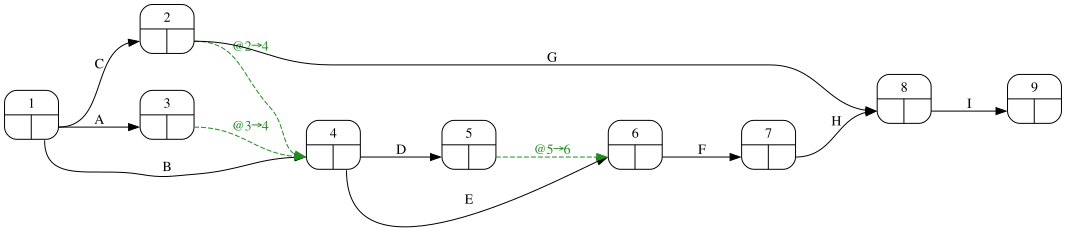

In [16]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)